In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
import numpy as np

In [6]:
df = pd.read_csv("../data/Dataset.csv")

In [7]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [8]:
df.tail()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV
8789,s8786,TV Show,YOM,Not Given,Pakistan,6/7/2018,2016,TV-Y7,1 Season,Kids' TV


In [9]:
df.describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [10]:
print(df.shape)


(8790, 10)


In [11]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB
None


In [12]:
print(df.isnull().sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [13]:

features = [
    "title",
    "type",
    "director",
    "country",
    "rating",
    "listed_in"
]
data = df[features].copy()


data = data.fillna("")

data = data.drop_duplicates(
    subset=["title", "type"]
).reset_index(drop=True)

data["combined_features"] = (
    data["listed_in"].str.replace(",", " ", regex=False).str.lower() + " " +
    data["listed_in"].str.replace(",", " ", regex=False).str.lower() + " " +
    data["director"].str.lower() + " " +
    data["country"].str.lower() + " " +
    data["type"].str.lower() + " " +
    data["rating"].str.lower()
)

print(data[["title", "combined_features"]].head())

                              title  \
0              Dick Johnson Is Dead   
1                         Ganglands   
2                     Midnight Mass   
3  Confessions of an Invisible Girl   
4                           Sankofa   

                                   combined_features  
0  documentaries documentaries kirsten johnson un...  
1  crime tv shows  international tv shows  tv act...  
2  tv dramas  tv horror  tv mysteries tv dramas  ...  
3  children & family movies  comedies children & ...  
4  dramas  independent movies  international movi...  


In [14]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

tfidf_matrix = tfidf.fit_transform(
    data["combined_features"]
)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (8787, 5000)


In [15]:
from sklearn.metrics.pairwise import cosine_similarity

def recommend(title, top_n=5):

    # Find title (case-insensitive)
    matches = data[
        data["title"].str.lower() == title.lower().strip()
    ]

    if matches.empty:
        return "Title not found in Netflix dataset."

    # Get selected content index
    idx = matches.index[0]

    # Calculate similarity with all other titles
    similarity_scores = cosine_similarity(
        tfidf_matrix[idx],
        tfidf_matrix
    ).flatten()

    # Exclude the selected title
    similarity_scores[idx] = -1

    # Get top matching indices
    top_indices = similarity_scores.argsort()[::-1][:top_n]

    # Prepare results
    recommendations = data.loc[
        top_indices,
        ["title", "type", "listed_in"]
    ].copy()

    recommendations["similarity_score"] = (
        similarity_scores[top_indices].round(3)
    )

    return recommendations.reset_index(drop=True)

In [16]:
print(recommend("Midnight Mass", top_n=10))

                        title     type                              listed_in  \
0  The Haunting of Hill House  TV Show     TV Dramas, TV Horror, TV Mysteries   
1   The Haunting of Bly Manor  TV Show     TV Dramas, TV Horror, TV Mysteries   
2     Brand New Cherry Flavor  TV Show     TV Dramas, TV Horror, TV Mysteries   
3                     Ratched  TV Show     TV Dramas, TV Horror, TV Mysteries   
4               The Originals  TV Show     TV Dramas, TV Horror, TV Mysteries   
5                    The Mist  TV Show     TV Dramas, TV Horror, TV Mysteries   
6                   Lost Girl  TV Show     TV Dramas, TV Horror, TV Mysteries   
7              Penny Dreadful  TV Show     TV Dramas, TV Horror, TV Mysteries   
8       American Horror Story  TV Show  TV Horror, TV Mysteries, TV Thrillers   
9                    Hannibal  TV Show  TV Horror, TV Mysteries, TV Thrillers   

   similarity_score  
0             0.851  
1             0.851  
2             0.851  
3             0.851 

In [17]:
def evaluate_recommendations(title, top_n=5):

    matches = data[
        data["title"].str.lower() == title.lower().strip()
    ]

    if matches.empty:
        return "Title not found."

    original_genres = set(
        matches.iloc[0]["listed_in"].lower().split(", ")
    )

    results = recommend(title, top_n)

    scores = []

    for genres in results["listed_in"]:

        recommended_genres = set(
            genres.lower().split(", ")
        )

        union = original_genres | recommended_genres
        intersection = original_genres & recommended_genres

        score = len(intersection) / len(union) if union else 0

        scores.append(score)

    results["genre_overlap"] = scores

    print("Average Genre Overlap:", round(np.mean(scores), 3))

    return results


print(evaluate_recommendations("Ganglands"))

Average Genre Overlap: 1.0
           title     type                                          listed_in  \
0     Crime Time  TV Show  Crime TV Shows, International TV Shows, TV Act...   
1          Lupin  TV Show  Crime TV Shows, International TV Shows, TV Act...   
2  Fatal Destiny  TV Show  Crime TV Shows, International TV Shows, TV Act...   
3   Agent Raghav  TV Show  Crime TV Shows, International TV Shows, TV Act...   
4        Smoking  TV Show  Crime TV Shows, International TV Shows, TV Act...   

   similarity_score  genre_overlap  
0             0.853            1.0  
1             0.853            1.0  
2             0.810            1.0  
3             0.806            1.0  
4             0.806            1.0  


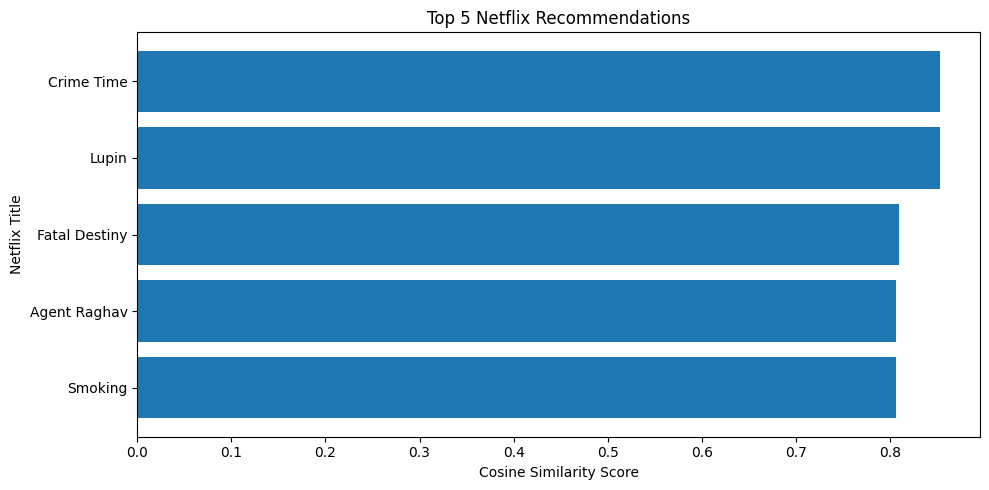

In [18]:
results = recommend("Ganglands", top_n=5)

plt.figure(figsize=(10, 5))

plt.barh(
    results["title"],
    results["similarity_score"]
)

plt.xlabel("Cosine Similarity Score")
plt.ylabel("Netflix Title")
plt.title("Top 5 Netflix Recommendations")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()